# GPU Warp Scheduling — Issue and Stall Analysis

**Goal:** Explain *why* a scheduler completes a workload faster or slower by measuring its issue behavior. We start with **Backprop**, then compare **NN** and **NW**.

This notebook uses the locally stored raw `*.log` simulation files (which are not committed to GitHub) and `results_validated.csv`. It makes **no new simulator runs**.

### Important counter interpretation

For each scheduler observation, GPGPU-Sim can report:

- **Idle** (`W0_Idle`): no valid instruction available.
- **Scoreboard** (`W0_Scoreboard`): valid instruction exists, but all considered instructions are blocked by RAW hazards.
- **Pipeline blocked**: a ready instruction cannot issue due to pipeline/resource availability.
- **Issue succeeded** (`single_issue_nums`): scheduler successfully issued one warp instruction.

The denominators below are **aggregated scheduler observations**, not unique GPU clock cycles. These counter shares help identify patterns, but do **not** alone prove causality.

## 1. Load inputs and select a workload

In [1]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SCHEDULERS = ["lrr", "gto", "rrr", "oldest"]
WORKLOAD = "nw"

root = Path.cwd().resolve()
if not (root / "results" / "feasibility" / "results_validated.csv").is_file():
    root = root.parent

results_dir = root / "results" / "feasibility"
validated_file = results_dir / "results_validated.csv"
if not validated_file.is_file():
    raise FileNotFoundError(f"Cannot find {validated_file}. Open the notebook from the repo root or notebooks/.")

perf = pd.read_csv(validated_file)
relevant = perf[(perf.workload == WORKLOAD) & perf.scheduler.isin(SCHEDULERS)].copy()
if len(relevant) != len(SCHEDULERS) or not (relevant.status == "PASS").all():
    raise ValueError(f"Missing or non-PASS validated performance results for {WORKLOAD}")
print("Validated performance data:")
display(relevant[["scheduler", "cycles", "instructions", "ipc"]].set_index("scheduler").reindex(SCHEDULERS))

Validated performance data:


,cycles,instructions,ipc
scheduler,,,
lrr,133487,572068,4.2856
gto,133487,572068,4.2856
rrr,133448,572068,4.2868
oldest,133487,572068,4.2856


## 2. Extract the **last** printed statistics from each log

The logs can contain multiple statistics reports because a workload can launch multiple kernels. We use the final report, which contains the cumulative shader statistics. For issued-instruction reconciliation, `W1` through `W32` count how many issued warp instructions had that many active lanes.

In [2]:
def last_match(pattern, content, label, log_path):
    matches = re.findall(pattern, content, flags=re.MULTILINE)
    if not matches:
        raise ValueError(f"Missing {label} in {log_path}")
    return matches[-1]


def extract_issue_stats(workload, scheduler):
    log_path = results_dir / f"{workload}-{scheduler}.log"
    if not log_path.is_file():
        raise FileNotFoundError(
            f"Cannot find {log_path}. The raw .log files must still exist locally."
        )
    content = log_path.read_text(encoding="utf-8", errors="replace")

    occupancy_line = last_match(
        r"^Warp Occupancy Distribution:\s*\n([^\n]+)",
        content, "Warp Occupancy Distribution", log_path
    )
    single_line = last_match(
        r"^single_issue_nums:\s*([^\n]+)",
        content, "single_issue_nums", log_path
    )
    dual_line = last_match(
        r"^dual_issue_nums:\s*([^\n]+)",
        content, "dual_issue_nums", log_path
    )

    def get_field(name):
        found = re.search(rf"\b{re.escape(name)}:(\d+)", occupancy_line)
        if not found:
            raise ValueError(f"Missing {name} in {log_path}")
        return int(found.group(1))

    single_counts = [int(v) for v in re.findall(r"\bWS\d+:(\d+)", single_line)]
    dual_counts = [int(v) for v in re.findall(r"\bWS\d+:(\d+)", dual_line)]
    lanes = {int(k): int(v) for k, v in re.findall(r"\bW(\d+):(\d+)", occupancy_line)}
    if len(single_counts) != 4 or len(dual_counts) != 4 or set(lanes) != set(range(1, 33)):
        raise ValueError(f"Unexpected scheduler/lane count format in {log_path}")

    single_issues, dual_issues = sum(single_counts), sum(dual_counts)
    if dual_issues != 0:
        raise ValueError(
            f"{log_path}: {dual_issues} dual-issue events. "
            "Cannot infer zero-active-lane issues safely from event counts alone."
        )
    nonzero_lane_issues = sum(lanes.values())
    zero_lane_issues = single_issues - nonzero_lane_issues
    raw_stall = get_field("Stall")
    pipeline_blocked = raw_stall - zero_lane_issues

    if zero_lane_issues < 0 or pipeline_blocked < 0:
        raise ValueError(
            f"Counter reconciliation failed for {log_path}: "
            f"zero_lane_issues={zero_lane_issues}, pipeline_blocked={pipeline_blocked}"
        )

    idle = get_field("W0_Idle")
    scoreboard = get_field("W0_Scoreboard")
    scheduler_observations = idle + scoreboard + pipeline_blocked + single_issues
    return dict(
        scheduler=scheduler,
        idle=idle,
        scoreboard=scoreboard,
        pipeline_blocked=pipeline_blocked,
        issued=single_issues,
        zero_lane_issues=zero_lane_issues,
        raw_stall=raw_stall,
        nonzero_lane_issues=nonzero_lane_issues,
        observations=scheduler_observations,
    )


stats = pd.DataFrame([extract_issue_stats(WORKLOAD, s) for s in SCHEDULERS])
stats = stats.set_index("scheduler").reindex(SCHEDULERS)
print("Raw counters and corrected pipeline stalls:")
display(stats[["idle", "scoreboard", "pipeline_blocked", "issued", "zero_lane_issues", "raw_stall", "observations"]])

Raw counters and corrected pipeline stalls:


,idle,scoreboard,pipeline_blocked,issued,zero_lane_issues,raw_stall,observations
scheduler,,,,,,,
lrr,761008,184436,2012,50496,128,2140,997952
gto,761008,184436,2012,50496,128,2140,997952
rrr,760364,184484,1920,50496,128,2048,997264
oldest,761008,184436,2012,50496,128,2140,997952


## 3. Normalize by the number of scheduler observations

For each scheduler:

**Issue success rate = Successful issue events ÷ (Idle + Scoreboard + Corrected pipeline-blocked + Successful issue events) × 100%.**

The other outcome rates use the same denominator. Together, these four categories sum to 100%. A higher issue-success fraction means more of the *observed scheduler opportunities* issued an instruction—not necessarily proportionally higher application performance.

Percent of aggregated scheduler observations:


,Idle / no valid instruction,Scoreboard / RAW hazard,Pipeline blocked,Issue succeeded
scheduler,,,,
lrr,76.26,18.48,0.20,5.06
gto,76.26,18.48,0.20,5.06
rrr,76.25,18.50,0.19,5.06
oldest,76.26,18.48,0.20,5.06


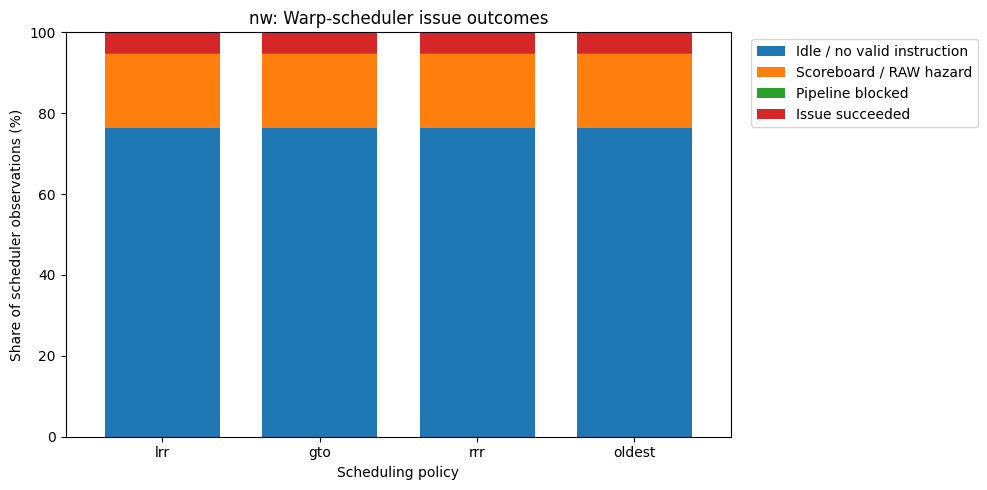

In [3]:
outcomes = ["idle", "scoreboard", "pipeline_blocked", "issued"]
share = stats[outcomes].div(stats["observations"], axis=0) * 100
share.columns = ["Idle / no valid instruction", "Scoreboard / RAW hazard", "Pipeline blocked", "Issue succeeded"]
print("Percent of aggregated scheduler observations:")
display(share.round(2))

ax = share.plot(kind="bar", stacked=True, figsize=(10, 5), width=0.73)
ax.set_title(f"{WORKLOAD}: Warp-scheduler issue outcomes")
ax.set_xlabel("Scheduling policy")
ax.set_ylabel("Share of scheduler observations (%)")
ax.set_ylim(0, 100)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
ax.tick_params(axis="x", labelrotation=0)
plt.tight_layout()
plt.show()

## 4. Compare performance and issue-success rate

Performance is measured in **whole-workload simulated cycles**. For the same workload, fewer cycles means faster completion. Issue success is a **scheduler-level rate**, not an IPC replacement.

,cycles,speedup_vs_lrr,observations,issued,zero_lane_issues,issue_success_pct,pipeline_blocked_pct,scoreboard_pct,idle_pct
scheduler,,,,,,,,,
lrr,133487,1.0,997952,50496,128,5.060,0.202,18.481,76.257
gto,133487,1.0,997952,50496,128,5.060,0.202,18.481,76.257
rrr,133448,1.0,997264,50496,128,5.063,0.193,18.499,76.245
oldest,133487,1.0,997952,50496,128,5.060,0.202,18.481,76.257


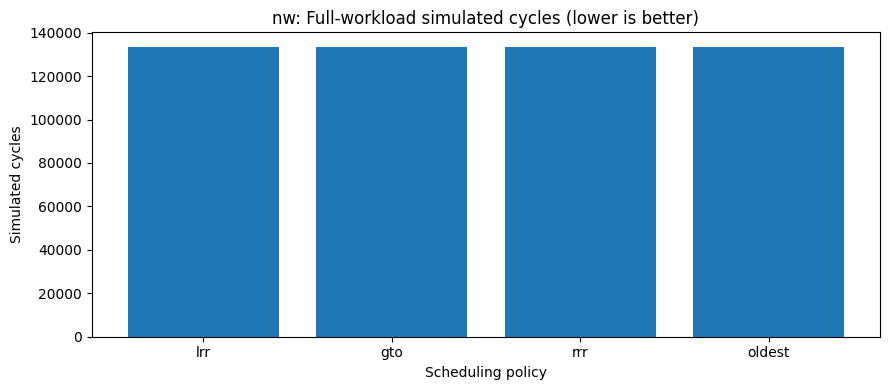

In [4]:
summary = stats[["observations", "issued", "zero_lane_issues"]].copy()
summary["issue_success_pct"] = share["Issue succeeded"]
summary["pipeline_blocked_pct"] = share["Pipeline blocked"]
summary["scoreboard_pct"] = share["Scoreboard / RAW hazard"]
summary["idle_pct"] = share["Idle / no valid instruction"]
cycles = relevant.set_index("scheduler").reindex(SCHEDULERS)["cycles"]
summary.insert(0, "cycles", cycles)
summary.insert(1, "speedup_vs_lrr", cycles.loc["lrr"] / cycles)
display(summary.round(3))

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(SCHEDULERS, summary["cycles"].to_numpy())
ax1.set_title(f"{WORKLOAD}: Full-workload simulated cycles (lower is better)")
ax1.set_ylabel("Simulated cycles")
ax1.set_xlabel("Scheduling policy")
plt.tight_layout()
plt.show()